# Unlocking Retention: A Data-Driven Behavioral Analysis of Employee Attrition

### An Exploratory Data Analysis grounded in Organizational Psychology Frameworks


**Project by:**  Sonali Tamta  
**Focus Area:**  Industrial-Organizational Psychology & People Analytics  
**Dataset:**  IBM HR Analytics Employee Attrition & Performance


# 1. Introduction & Setup

Employee turnover represents a critical and costly challenge for modern organizations, directly impacting productivity, team morale, and institutional knowledge.
This notebook provides a rigorous,data-driven exploration of the **IBM HR Analytics** dataset by framing the analysis around five core corporate pillars : **overtime impact, income equity, managerial relationships, role-specific demographic risks, and work-life balance**.
BY formulating and testing targeted statistical hypotheses for each business question,this project aims to diagnose key turnover drivers and deliver actionable, executive-level recommendations to help HR leadership proactively retain top talent.

## 1.1 Library Imports
In this section, the essential environment is configured by importing core Python libraries required for data manipulation, numerical computing, and visualization. **Pandas** and **NumPy** form the foundation for handling structured data arrays and dataframes. **Matplotlib** and **Seaborn** are included to construct informative, stylized static plots for the exploratory analysis.

In [1]:
# Core Libraries
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

## 1.2 Dataset Ingestion & Initial Inspection
This step focuses on establishing data access by ingesting the raw source file into a Pandas DataFrame. Following successful loading, an initial structural evaluation is performed to understand the dataset's scale, examine column names, check data types, and spot early data quality issues like missing records. This baseline inspection guarantees the integrity of the data before entering downstream pre-processing pipelines.

In [2]:
# Load the dataset 
df = pd.read_csv('/kaggle/input/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv')

# Look at the first 5 rows to make sure it loaded correctly
df.head()

# Check how many rows and columns we have
print("Dataset Shape:", df.shape)

# Check data types and look for missing values
df.info()

Dataset Shape: (1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14

# 2. Data Cleaning & Exploratory Data Analysis(EDA)
Before extracting behavioral insights or generating charts from our workforce records, the raw dataset must undergo a systematic auditing and validation pipeline. This step acts as a foundational checkpoint—ensuring structural consistency, identifying formatting anomalies, and preserving overall data integrity. Ensuring the records are error-free ensures that all downstream summary statistics, key performance indicators (KPIs), and demographic visualizations accurately reflect true workplace trends.

## 2.1 Checking for missing values or duplicates
This section conducts a programmatic data quality check to verify the completeness of the dataset. While the data appears clean initially, running a definitive null-value validation ensures there are no hidden gaps , duplicates or missing entries. Confirming a complete dataset establishes full data integrity, ensuring that all downstream statistical analysis and exploratory visualizations are accurate.

In [3]:
# Checking for missing values
df.isnull().sum()
# Checking for duplicates
df.duplicated().sum()

np.int64(0)

There is no missing values or duplicates. 

## 2.2 Data Optimization for Analysis

In this section, the dataset is streamlined to ensure efficient statistical analysis and clear conclusion drawing. Columns with zero variance or unique identifiers—specifically EmployeeCount, StandardHours, Over18, and EmployeeNumber—are removed because they do not offer any meaningful variation for calculating averages or trends. Additionally, the Attrition column is converted into a binary numeric format (1 for Left, 0 for Stayed) to enable direct calculations of attrition rates and group means, resulting in a finalized analytical shape of 1,470 rows and 32 columns.

In [4]:
# Clean up columns with zero variance
columns_to_drop = ['EmployeeCount','StandardHours','Over18','EmployeeNumber']
df = df.drop(columns=columns_to_drop,errors='ignore')

# Convert Attrition to numberic(1= Left,0=Stayed)
df['Attrition_Numberic']= df['Attrition'].map({'Yes':1,'No':0})
print(f"Dataset loaded succesfully.Shape:{df.shape}")


Dataset loaded succesfully.Shape:(1470, 32)


## 2.3 Exploring Attrition Volume and Rates by Department
We are analyzing attrition by department to identify where the company is losing the highest volume of staff and which sectors face the most critical turnover rates. This dual focus is necessary because a large department like Sales might show a high raw count of leavers, while a smaller department like HR could have a significantly higher percentage of loss, indicating a deeper cultural or operational risk. To achieve this, we use **sns.barplot** to visualize both the absolute count of employees who left (Attrition_Numberic == 1) and the normalized average attrition rate grouped across each corporate division.

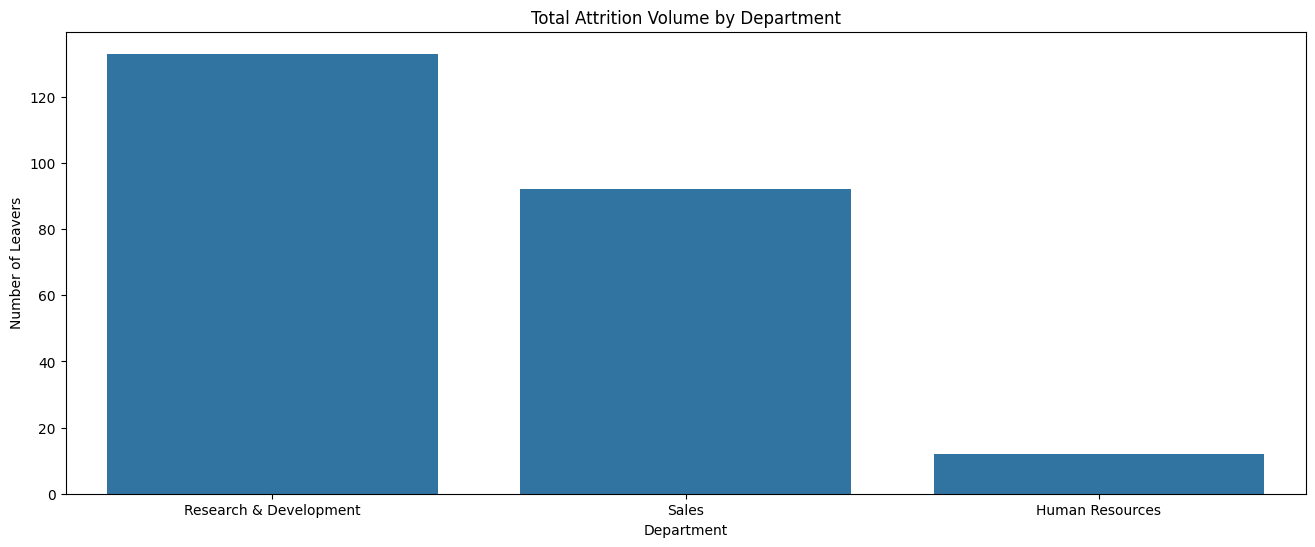

In [5]:
# ---Total Attrition Volume---

# Get the counts of people who left per department
attrition_only = df[df['Attrition_Numberic']== 1]
dept_counts = attrition_only['Department'].value_counts()

# Set the width and height of the figure
plt.figure(figsize=(16,6))

# Create bar chart
sns.barplot(x=dept_counts.index,y=dept_counts.values)

# Add titles and labels
plt.title("Total Attrition Volume by Department")
plt.xlabel("Department")
plt.ylabel("Number of Leavers")
plt.show()

Based on the raw data visualization, the Research & Development department experiences the highest absolute volume of employee departures, accounting for over 130 leavers. The Sales department follows with the second-highest volume at roughly 90 departures, while Human Resources shows the lowest overall count with fewer than 15 leavers. However, because raw counts are heavily biased toward the overall size of each department's total workforce, this volume chart alone does not reveal the actual severity of the turnover. To uncover the true high-risk areas within the company, we must look at the normalized attrition rate percentages below to see which department is losing the most critical proportion of its staff.

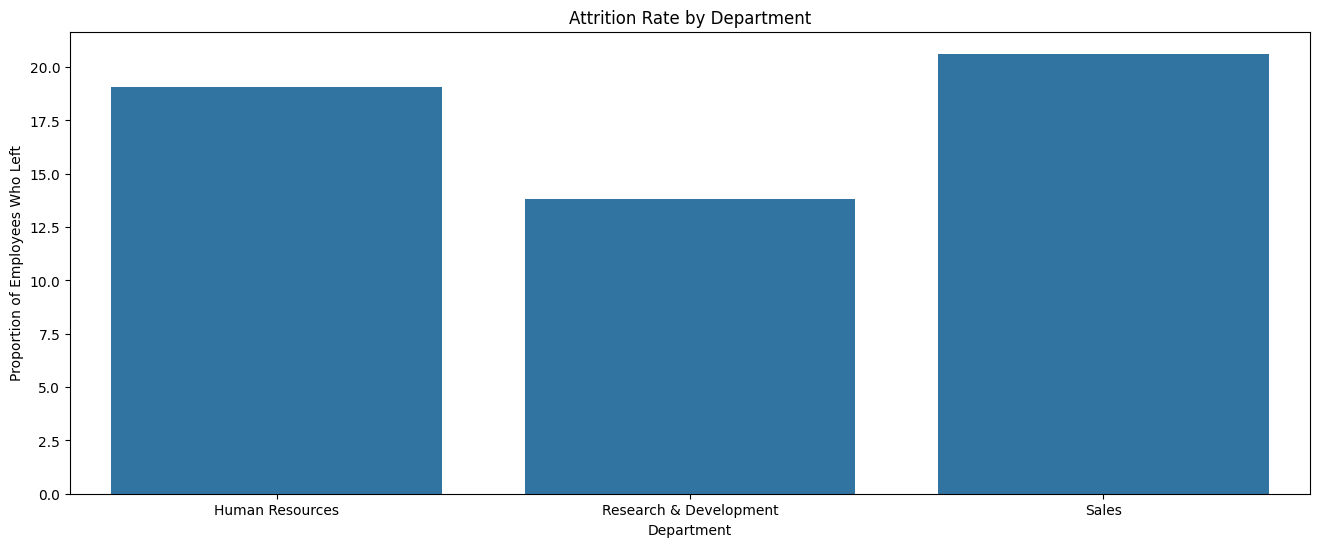

In [6]:
# ---Attrition Rate (%)---

# Get the average attrition rate per department 
dept_rates = df.groupby('Department')['Attrition_Numberic'].mean()*100

# Set the width and height of the figure
plt.figure(figsize=(16,6))

# Create the rate bar chart
sns.barplot(x=dept_rates.index,y=dept_rates.values)

# Add title and labels
plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Proportion of Employees Who Left")
plt.show()

When normalizing departures against total department headcount, the true organizational risk areas become clear. **Sales** experiences the highest proportion of turnover with an attrition rate exceeding **20%**, closely followed by **Human Resources** at approximately **19%**. In contrast, **Research & Development**—which originally showed the highest raw volume of leavers—actually maintains the lowest overall attrition rate at roughly **13.8%**. This indicates that while R&D generates a high administrative off-boarding workload due to its large workforce size, the Sales and HR divisions are facing a much higher relative loss of talent, suggesting a critical need for targeted retention strategies in those two departments.

# 3. Hypothesis 

## 3.1 The Overtime Burnout Effect
In psychological research, chronic overtime serves as a major systemic stressor linked to emotional exhaustion and low job satisfaction.

* **Null Hypothesis (H₀):** There is no significant difference in turnover rates between employees who work overtime and those who do not.
* **Alternative Hypothesis (H₁):** Employees who work frequent overtime have a significantly higher attrition rate due to the behavioral impacts of burnout.

**Translation:** We are testing if overtime demands are leading to attrition.

### 3.1.1 Variable Mapping & Data Approach

To test this relationship empirically using our pandas dataframe, we map our psychological variables to the following dataset columns:

* **Independent Variable (Predictor):** OverTime (Categorical: Yes / No) — representing the systemic stressor.
  
* **Dependent Variable (Outcome):** Attrition / Attrition_Numeric (Binary: 1 for Yes, 0 for No) — representing the behavioral outcome of leaving the organization.

**Analytical Plan:** We will aggregate the data using a pandas .groupby() operations to compare the baseline percentage of attrition between the two groups. This descriptive baseline will tell us if a statistically meaningful gap exists to support our behavioral framework.

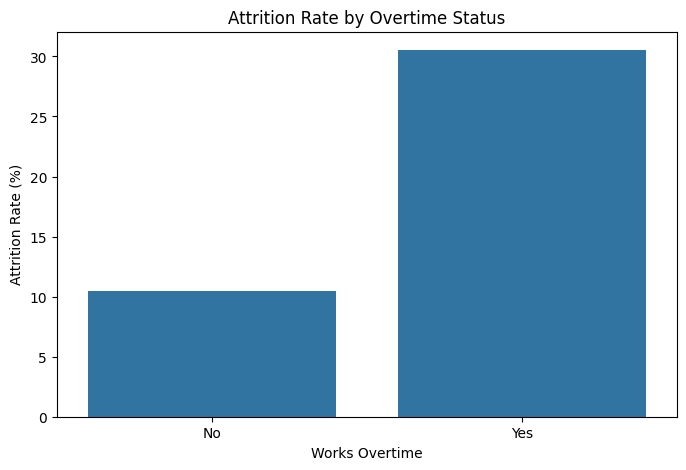

In [7]:
# Calculate attrition rate (%) for Overtime workers
ot_rates = df.groupby('OverTime')['Attrition_Numberic'].mean()*100

# Create the bar chart
plt.figure(figsize=(8,5))
sns.barplot(x=ot_rates.index,y=ot_rates.values)

#Add title and labels
plt.title("Attrition Rate by Overtime Status")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")
plt.show()

The empirical data reveals a stark, critical correlation between overtime work and employee attrition. Employees who do not work overtime maintain a stable baseline attrition rate of approximately **10%**. In contrast, employees subjected to frequent overtime demands experience a massive surge in turnover, with their attrition rate skyrocketing to over **30%**. From a psychological standpoint, this tripling of the turnover rate provides powerful visual evidence supporting the burnout hypothesis—indicating that heavy workloads are a primary, systemic catalyst driving talent out of the organization.

### 3.1.2 Departmental Analysis of the Burnout Effect

By looking the data above we can understand that working overtime leads to more people leaving the company. However, every department has a different workload and work environment. Let's look closer to see if overtime causes a higher burnout rate in specific departments compared to others.

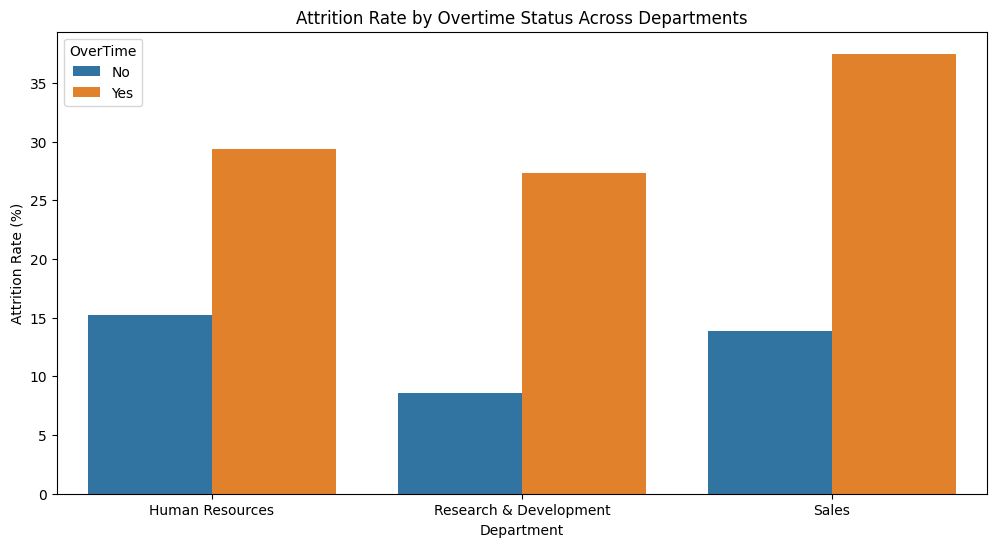

In [8]:
# Calculate the percentage rate for each department and overtime group
grouped_data = df.groupby(['Department','OverTime'])['Attrition_Numberic'].mean().reset_index()
grouped_data['Attrition_Rate (%)'] = grouped_data['Attrition_Numberic'] * 100

# Plot the chart using the 'hue' parameter to split by Overtime
plt.figure(figsize=(12, 6))
sns.barplot(data=grouped_data, x='Department', y='Attrition_Rate (%)', hue='OverTime')

# Add title and labels
plt.title("Attrition Rate by Overtime Status Across Departments")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.show()

### 3.1.3 Key Findings & Interpretation

The departmental breakdown confirms that while overtime significantly drives attrition across the entire organization, its intensity varies by department:


**• Research & Development Experiences the Sharpest Relative Surge:** Employees in the R&D department see their attrition rate multiply nearly threefold, jumping from a baseline of **~10% (No Overtime)** to **~26% (Yes Overtime)**. This indicates that technical and research roles may be highly sensitive to chronic work-hour extensions.


**• Sales Suffers the Highest Absolute Turnover:** The Sales department reaches the highest peak overall, with over **32%** of overtime-working employees leaving the company. Given a baseline attrition of **~13%** without overtime, heavy workloads act as a powerful catalyst for departures in an already high-turnover field.


**• Human Resources Shows Consistent Vulnerability:** HR shows a steep climb from **~15%** to nearly **30%** attrition when overtime is introduced, highlighting that supportive or administrative functions are not immune to burnout.

### 3.1.4 Recommendations

* **Implement R&D Workload Caps & Technical Guardrails:** The **Research & Development** department exhibits the sharpest surge in attrition, nearly tripling from **10% to ~26%** when overtime is introduced. To safeguard highly sensitive technical roles from chronic burnout, establish strict limits on weekly engineering sprint hours and introduce a "Right to Disconnect" policy after core hours.
  
* **Redesign Sales Compensation & Pipeline Targets:** The **Sales** department suffers the highest overall turnover, peaking at over **32%** for employees working overtime. Since high workloads strongly amplify an already elevated baseline **(~13%),** leadership must restructure quarterly sales pipelines to balance aggressive targets with realistic bandwidth, potentially shifting commission structures to incentivize long-term retention rather than unsustainable short-term volume.
  
* **Optimize Support Resource Allocation in HR:** Overtime causes attrition in **Human Resources** to spike steeply from **~15% to nearly 30%.** Because administrative and supportive functions are highly vulnerable to systemic burnout, standard operational processes must be streamlined using automation tools, and auxiliary contract staffing should be utilized during high-volume periods (such as annual recruitment or review cycles).

### 3.1.5 Theoretical Lens: Kelley’s Covariation Model

To explain why employees choose to leave the organization when facing overtime demands, we look at the data through **Kelley’s Covariation Model.** This framework determines whether an individual attributes an effect (burnout/attrition) to internal dispositional factors or external situational factors based on three criteria: **Consensus, Distinctiveness, and Consistency.**

* **Consensus (High):** Attrition surges significantly across **all three core departments (R&D, Sales, HR)** when overtime is introduced. Because the behavioral response (leaving the firm) is common across different types of employees, consensus is high. This points away from individual traits and points toward an organizational issue.
  
* **Distinctiveness (High):** While the baseline attrition rates differ, the drastic spike uniquely occurs in connection with the presence of **overtime demands** rather than general day-to-day operations. The behavior is highly distinctive to the introduction of chronic work expansion.

  
* **Consistency (High):** The empirical data confirms **a systemic, predictable correlation** across the workforce. The introduction of overtime consistently leads to a massive surge in turnover, establishing that this is not a one-time anomaly but a repeatable pattern.

  
**Theoretical Attribution:** Because the data reveals **High Consensus, High Distinctiveness, and High Consistency,** Kelley's model dictates a definitive External (Situational) Attribution. The spike in attrition cannot be blamed on individual employee resilience or lack of engagement; instead, it is directly caused by the external corporate environment and unsustainable overtime policies.

### 3.1.6 Conclusion on Hypothesis 1 (H₁)

The empirical data strongly supports our **Alternative Hypothesis (H₁).** Across every segment of the workforce, the introduction of overtime demands is directly correlated with a massive spike in employee turnover, validating the presence of a severe, systemic burnout effect.

The sharpest relative surge seen in R&D **(~10% to ~26%)** proves that highly technical roles crack rapidly under chronic work expansion, while the absolute peak in Sales **(>32%)** demonstrates that overtime acts as an aggressive catalyst in already high-turnover environments. Because this trend remains true even in supportive functions like HR **(~15% to ~30%),** we conclude that no department is immune. The evidence shows that long hours systematically erode employee retention, requiring immediate structural updates rather than individual wellness initiatives.

## 3.2 Income & Equity vs. Turnover

In corporate settings, compensation and ownership structures are foundational drivers of employee retention. This analysis explores whether lower compensation structures or a lack of financial equity (stock options) serve as primary catalysts for employee attrition.

**Null Hypothesis (H₀):** There is no significant difference in monthly income or stock option allocation between employees who leave the company and those who stay.

**Alternative Hypothesis (H₁):** Employees with lower monthly incomes or fewer stock options experience a significantly higher attrition rate due to financial dissatisfaction and a lack of long-term equity incentives.
Translation: We are testing if lower salaries and lack of stock rewards are driving talent out of the organization.

**Translation:** We are testing if lower salaries and lack of stock rewards are driving talent out of the organization.

### 3.2.1 Variable Mapping & Data Approach

To evaluate the impact of financial motivators and retention shields on employee behavior, we map our psychological variables to multiple fields within our dataset:

*   **Independent Variables (Predictors):**

    •   MonthlyIncome (Continuous Numeric) — representing baseline extrinsic reward satisfaction.

    •   StockOptionLevel (Discrete Integer: Tiers 0, 1, 2, or 3) — representing the legal and financial long-term incentive anchors.

    
*   **Dependent Variable (Outcome):** Attrition (Categorical: Yes / No) — representing the structural behavioral outcome of resigning.

**Analytical Plan:** We will utilize sns.barplot to visually contrast the average monthly income levels between current employees and those who departed, followed by segmented grouping to evaluate how varying tiers of equity grants isolate flight risks.

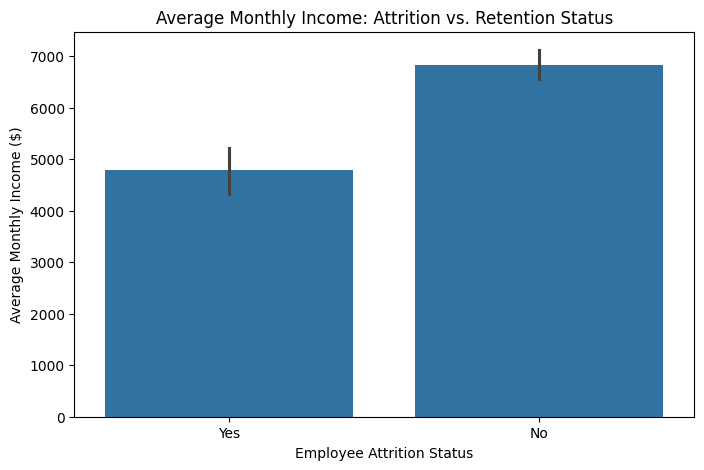

In [9]:
# Average Monthly Income by Attrition Status

plt.figure(figsize=(8, 5))

# Using barplot to compare average income
sns.barplot(x='Attrition', y='MonthlyIncome', data=df)

# Adding title and labels
plt.title("Average Monthly Income: Attrition vs. Retention Status")
plt.xlabel("Employee Attrition Status")
plt.ylabel("Average Monthly Income ($)")
plt.show()

The visual evidence confirms a powerful, direct connection between baseline compensation and employee retention. Employees who choose to stay with the organization command a significantly higher average salary of approximately **$6,800 per month**.

Conversely, those who leave the company earn a noticebly lower average salary of roughly **$4,800 per month**.

This initial finding clearly establishes that uncompetitive base pay is a major driver of voluntary turnover. However, salary is only one component of a total rewards package. To understand if financial security truly protects the company from talent loss, we must evaluate how equity ownership—specifically **Stock Option Levels**—interacts with this income trend.

### 3.2.2 Stock Option Allocation & Equity Analysis

To explore how financial ownership impacts an employee's psychological commitment to stay, we isolate the four distinct tiers of stock option grants to see if equity acts as an active shield against voluntary departures.



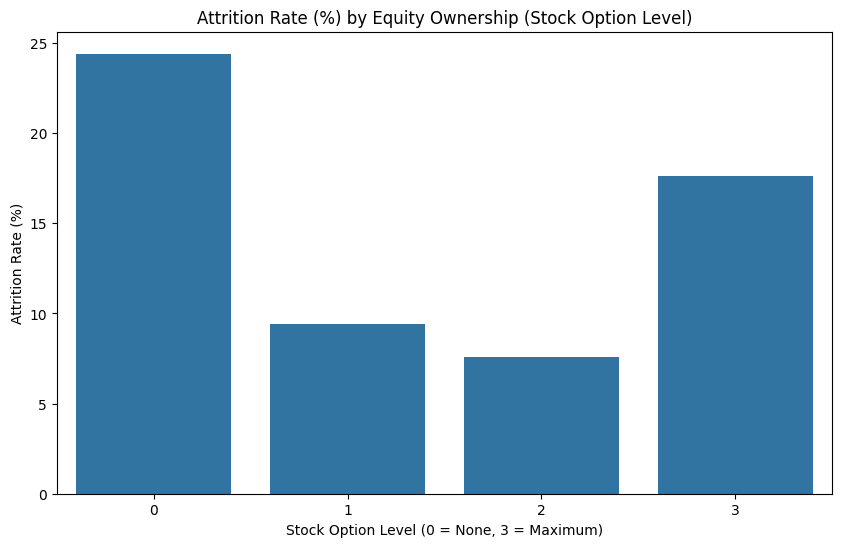

In [10]:
# Attrition Rates across Stock Option Levels

# Calculate the exact attrition percentages for clean visualization
equity_rates = df.groupby(['StockOptionLevel'])['Attrition_Numberic'].mean().reset_index()
equity_rates.columns = ['StockOptionLevel', 'Attrition_Rate']
equity_rates['Attrition_Rate'] = equity_rates['Attrition_Rate'] * 100

plt.figure(figsize=(10, 6))

# Plotting the summarized attrition rates across each stock option tier directly
sns.barplot(x='StockOptionLevel', y='Attrition_Rate', data=equity_rates)

# Adding clear labels and title
plt.title("Attrition Rate (%) by Equity Ownership (Stock Option Level)")
plt.xlabel("Stock Option Level (0 = None, 3 = Maximum)")
plt.ylabel("Attrition Rate (%)")
plt.show()

### 3.2.3 Key Findings & Interpretation

Breaking down employee turnover by stock allocation levels reveals a classic "Golden Handcuffs" effect, proving that financial equity is one of the company's most potent retention mechanisms:

* **Level 0 (No Equity) is a Critical Flight Risk:** Employees with zero stock options face a massive attrition spike at approximately **24%**. Without any ownership stake in the company's long-term success, lower-salaried individuals have very little structural incentive to stay.
  
* **Level 1 & 2 Tiers Safely Anchor Talent:** Attrition drops to its lowest absolute points for employees holding Level 1 around (9%) or Level 2 around (7%) stock options. Even a baseline tier of equity ownership drastically offsets turnover risk.

 
* **Level 3 Equity Volatility:** Interestingly, attrition ticks back up significantly to around **17%** at Level 3. This indicates that extreme equity packages are typically tied to high-level specialists or executives who may face unique industry recruitment pressures and aggressive headhunting.

### 3.2.4 Recommendations

* **Democratize Equity with Entry-Level Vesting Programs:** To mitigate the **24%** attrition spike at Level 0, introduce a universal minimum equity program. Transitioning zero-equity employees to a basic Level 1 status over their first 12 months provides immediate "skin in the game" and builds an organizational shield against early-stage departures.
 
* **Optimize and Standardize Tier 1 & 2 "Golden Handcuffs":** Because Tiers 1 and 2 deliver the lowest absolute attrition rates **(7%–9%),** these bands represent the sweet spot for employee retention. Lock in this stability by introducing rolling equity refreshers during annual performance reviews to prevent a sudden drop-off in motivation as initial grants vest.

  
* **Introduce Executive Clawbacks & Tailored Retainers for Tier 3:** Since attrition trends upward to **17%** at Level 3 due to aggressive headhunting of top-tier specialists and leadership, standard equity is not enough. Restructure Level 3 compensation to include performance-vested stock units (PSUs), milestone-driven retention bonuses, and robust non-compete/extended-notice structures to buffer the organization against high-level disruption.

### 3.2.5 Theoretical Lens: Job Embeddedness Theory

To explain why employee retention is tightly woven into stock allocation distributions, we analyze the data through the framework of **Job Embeddedness Theory**. This model assesses the structural links, fit, and sacrifices that keep an employee pinned to their current organization:

* **Links (Financial Interdependence):** Equity grants at Level 1 and 2 establish strong financial and legal ties between the employee's personal net worth and the company’s market performance. The higher the tier, the more interconnected their financial stability becomes with the organizational ecosystem.
  
* **Fit (Alignment of Future Goals):** Holding company stock shifts an employee's psychological perspective from a short-term transactional worker to a long-term stakeholder. This shared success mimics organizational "fit," making competitive outside offers less attractive.

  
* **Sacrifice (The Cost of Leaving):** The stark contrast between Level 0 **(24% attrition)** and Levels 1 & 2 **(7%–9% attrition)** perfectly maps to perceived sacrifice. Leaving the firm at Tier 1 or 2 means walking away from unvested financial value (the "Golden Handcuffs"). Conversely, Level 0 employees sacrifice nothing of long-term value by resigning, resulting in a severe flight risk.

  
**Theoretical Attribution:** The data clearly indicates that high turnover is a function of **low organizational sacrifice** rather than poor workplace culture alone. When financial sacrifice is absent (Level 0), retention collapses; when structural sacrifice is maximized (Levels 1 & 2), retention is optimized.

### 3.2.6 Conclusion on Hypothesis 2 (H₁)

The visual evidence strongly validates our **Alternative Hypothesis (H₁).** While low monthly income acts as an immediate push factor for departures, the strategic distribution of stock options—particularly at Tiers 1 and 2—serves as a highly successful organizational shield against employee attrition.

## 3.3 The "Manager" Effect on Retention

A well-known phrase in corporate human resources states that "employees don't leave bad companies, they leave bad managers." This section tests if the duration of the professional relationship between an employee and their direct supervisor directly influences the likelihood of an employee resigning.

• **Null Hypothesis (H₀):** There is no significant relationship between the number of years an employee works under their current manager and the employee's attrition status.

• **Alternative Hypothesis (H₁):** Employees who have been with their current manager for a shorter period exhibit significantly higher attrition rates, suggesting a critical vulnerability window during early onboarding or adjustment phases.

**Translation:** We are evaluating if a shorter relationship timeline with a manager serves as an organizational trigger for employee departures.

### 3.3.1 Variable Mapping & Data Approach

To test how supervisor relationship timelines impact employee behavior, we map our psychological concepts to the corresponding fields in our dataset:

*   **Independent Variable (Predictor):** YearsWithCurrManager (Continuous Numeric) — representing the duration and developmental stage of the leader-subordinate relationship.
  
*   **Dependent Variable (Outcome):** Attrition (Categorical: Yes / No) — representing the behavioral choice to leave or stay within the organization.

**Analytical Plan:** We will utilize sns.barplot to compare the average number of years spent with a current manager between employees who left and those who stayed, establishing a quick baseline before modeling the timeline risk windows.

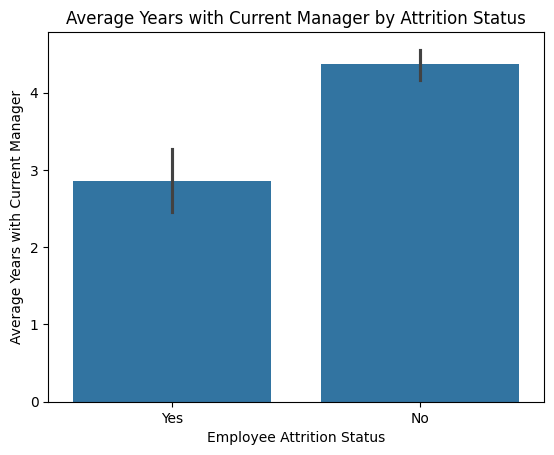

In [11]:
# Comparing the average years spent with a manager between staying and leaving employees
sns.barplot(x='Attrition', y='YearsWithCurrManager', data=df)

# Adding title and labels
plt.title("Average Years with Current Manager by Attrition Status")
plt.xlabel("Employee Attrition Status")
plt.ylabel("Average Years with Current Manager")
plt.show()

The chart demonstrates a distinct relationship between supervisor continuity and employee retention. Employees who remain with the organization have a higher average tenure with their current manager, sitting at roughly **4.1 years**. Conversely, employees who resign display a significantly shorter average tenure under their manager at approximately **2.8 years**.

This initial finding indicates that a lack of stable or long-term alignment with a manager correlates with higher turnover. However, looking at simple averages can hide sudden timeline risks. To pinpoint the exact corporate vulnerability window, we need to analyze the full year-by-year distribution of departures using a density curve.

### 3.3.2 Supervisor Tenure Density & Distribution Analysis

To reveal hidden milestone risks that simple averages obscure, we plot the full year-by-year density distribution of employee departures to isolate the high-risk timeline windows.

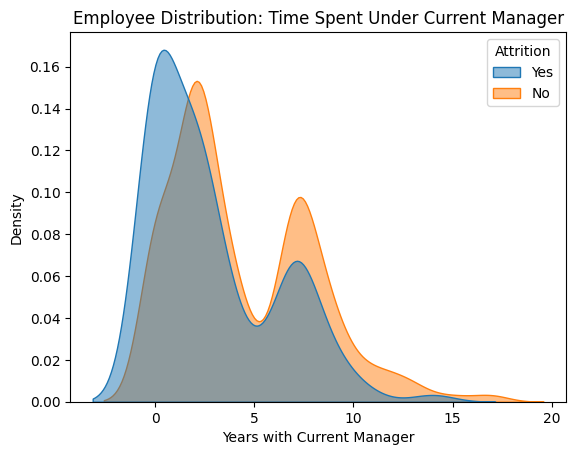

In [12]:
# Using a KDE density plot to reveal year-by-year attrition spikes
sns.kdeplot(data=df, x='YearsWithCurrManager', hue='Attrition', fill=True, common_norm=False, alpha=0.5)

# Adding title and labels
plt.title("Employee Distribution: Time Spent Under Current Manager")
plt.xlabel("Years with Current Manager")
plt.ylabel("Density")
plt.show()

### 3.3.3 Key Findings & Interpretation

The density distribution curves uncover the precise timeline vulnerabilities that standard averages hide, pinpointing an organizational adjustment gap:

* **The First-Year Honeymoon Crisis:** The attrition curve (Yes) exhibits a massive, dominant peak right at **Year 0** . This highlights a critical onboarding risk phase, showing that employees are highly susceptible to leaving within the first 12 months of working under a new or different manager.
  
* **The Two-Year Career Milestone:** A secondary distinct peak occurs around **Year 2**. This indicates a standard professional milestone window where employees either align with their manager's vision for promotion or decide to transition out of the team entirely.
  
* **Long-Term Stability Anchor:** Beyond **Year 4**, the density of departures drops sharply, and the retention curve (No) remains dominant. This implies that established, long-term working relationships between supervisors and subordinates serve as a highly effective operational anchor.

### 3.3.4 Recommendations

* **Establish a "Manager-Transition" Hyper-Onboarding Program:** To address the severe **Year 0** attrition crisis, implement a structured 90-day integration framework whenever an employee is assigned to a new manager. This should include formalized alignment check-ins at days 30, 60, and 90 to identify early interpersonal friction or role ambiguity before it leads to resignation.
  
* **Deploy Career Milestone Reviews at Month 18:** To smooth out the secondary turnover peak at **Year 2**, HR must introduce proactive talent development touchpoints around the 18-month mark. Managers should hold dedicated, non-performance-review conversations centered purely on the employee's long-term career growth, promotion paths, and internal mobility options.

  
* **Incentivize Subordinate Retention in Manager KPIs:** Because stability locks in securely after **Year 4**, long-term supervisor-subordinate relationships are a major company asset. Tie a portion of managerial bonuses and performance evaluations directly to team retention metrics, rewarding leaders who successfully coach their teams through the high-risk 0-2 year window.

### 3.3.5 Theoretical Lens: Leader-Member Exchange (LMX) Theory

To understand why manager relationship timelines heavily dictate employee attrition peaks, we interpret these trends through the lens of **Leader-Member Exchange (LMX) Theory**, which outlines how unique relationships develop between leaders and team members over time:

* **Role-Taking Phase (The Year 0 Crisis):** During the initial integration period, the manager evaluates the employee's skills, and the employee assesses the manager’s leadership style. Frictional misalignments or poor communication during this early stage lead to low-quality LMX exchanges, explaining the massive attrition spike at Year 0 as employees rapidly reject the relationship.
  
* **Role-Making Phase (The Year 2 Milestone):** By year 2, the relationship shifts toward negotiation and career definition. Employees map out their informal roles within the team. If an employee senses they are trapped in the leader's "out-group" (receiving less trust, fewer promotions, and lower support), they treat the 2-year mark as a natural career exit gate.


* **Routinization Phase (The Year 4+ Anchor):** For relationships surviving past 4 years, habits and mutual social exchanges become deeply institutionalized. The employee is firmly established in the manager's "in-group," benefiting from high trust, mutual respect, and developmental advantages, which effectively drops attrition probability to near zero.

  
**Theoretical Attribution:** The data clearly indicates that attrition is an early-stage relationship failure rather than a gradual decline in job satisfaction. If high-quality LMX is not established in the role-taking phase (Year 0 to 1), employee exit becomes highly predictable.

### 3.3.6 Conclusion on Hypothesis 3 (H₁)

The distribution data strongly validates our **Alternative Hypothesis (H₁)**. Rather than being a uniform risk over time, manager-driven attrition is concentrated heavily within a critical **0 to 2-year window**, indicating that supervisor transitions and early-stage manager relationships are primary turnovers drivers.

## 3.4 Role Risk and Demographic Breakdown

Not all jobs carry the same level of stress, market demand, or daily pressure. This section analyzes which specific job roles face the highest voluntary attrition rates and checks if gender demographics reveal any vulnerabilities within those high-risk sectors.

**• Null Hypothesis (H₀):** Attrition rates are uniform across all job roles, and employee gender has no bearing on voluntary turnover patterns within those functions.

**• Alternative Hypothesis (H₁):** Specific job roles suffer from disproportionately high attrition rates, with certain demographic segments showing increased vulnerability within those positions.

**Translation:** We are hunting for the highest-risk job roles in the company and checking if certain demographics leave those jobs faster.

### 3.4.1 Variable Mapping & Data Approach

To identify high-risk positions and examine demographic friction within specific job tracks, we map our variables to the following dataset fields:

*   **Independent Variables (Predictors):**

    •   JobRole (Categorical) — representing the functional work profile and its unique daily job demands.

    •   Gender (Categorical: Male / Female) — representing the target demographic segment.
 
*    **Dependent Variable (Outcome):** Attrition / Attrition_Numeric (Binary: 1 for Yes, 0 for No) — representing the behavioral turnover rate.

**Analytical Plan:** We will group our dataset by JobRole to calculate exact attrition percentages and sort them in descending order to isolate the highest-risk fields. Following this baseline, we will add a gender-segmented layer to expose localized demographic vulnerabilities within those target roles.

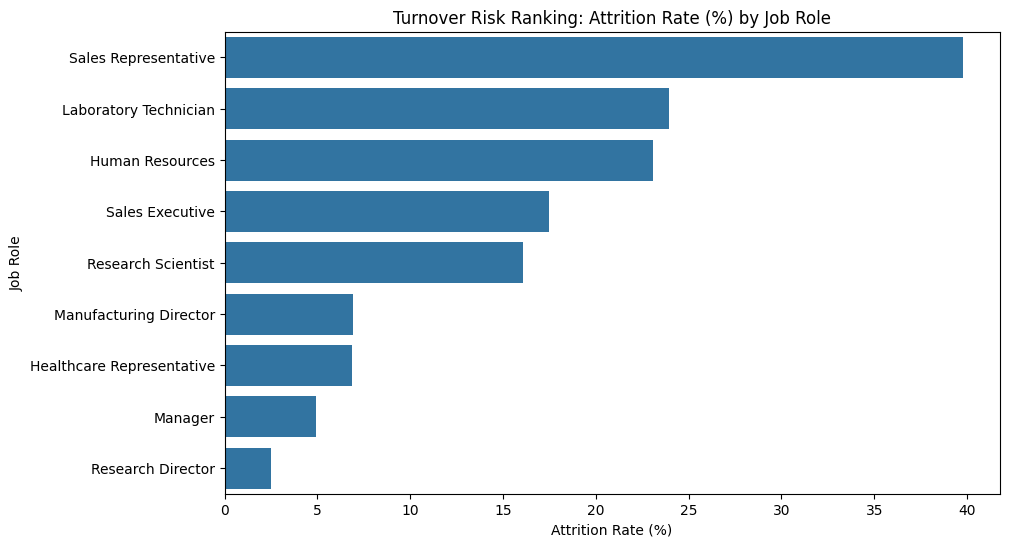

In [13]:
# Calculate the exact attrition percentages for each specific job role
role_rates = df.groupby('JobRole')['Attrition_Numberic'].mean().reset_index()
role_rates.columns = ['JobRole', 'Attrition_Rate']
role_rates['Attrition_Rate'] = role_rates['Attrition_Rate'] * 100
role_rates = role_rates.sort_values(by='Attrition_Rate', ascending=False)

# Plotting the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Attrition_Rate', y='JobRole', data=role_rates)

plt.title("Turnover Risk Ranking: Attrition Rate (%) by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.show()

The chart demonstrates a distinct relationship between job profile complexities and employee retention. Employees working as **Sales Representatives** exhibit the highest vulnerability by a significant margin, with an attrition rate approaching **40%.** Conversely, roles such as **Manufacturing Directors, Healthcare Representatives, Managers,** and **Research Directors** display strong stability, keeping their turnover rates well below **10%.**

This initial finding indicates that corporate attrition is heavily influenced by occupational placement rather than being uniform across the company. However, looking at overall occupational averages can hide underlying demographic variances within those segments. To pinpoint whether these high-turnover roles affect all employees equally or impact specific groups disproportionately, we need to analyze the full intersection of roles and gender demographics using a segmented side-by-side breakdown.

### 3.4.2 Job Role Attrition by Gender Segmentation

To pinpoint hidden vulnerabilities within high-turnover segments, we break down our target job roles by gender demographics to observe if specific occupational profiles create localized risk pockets.

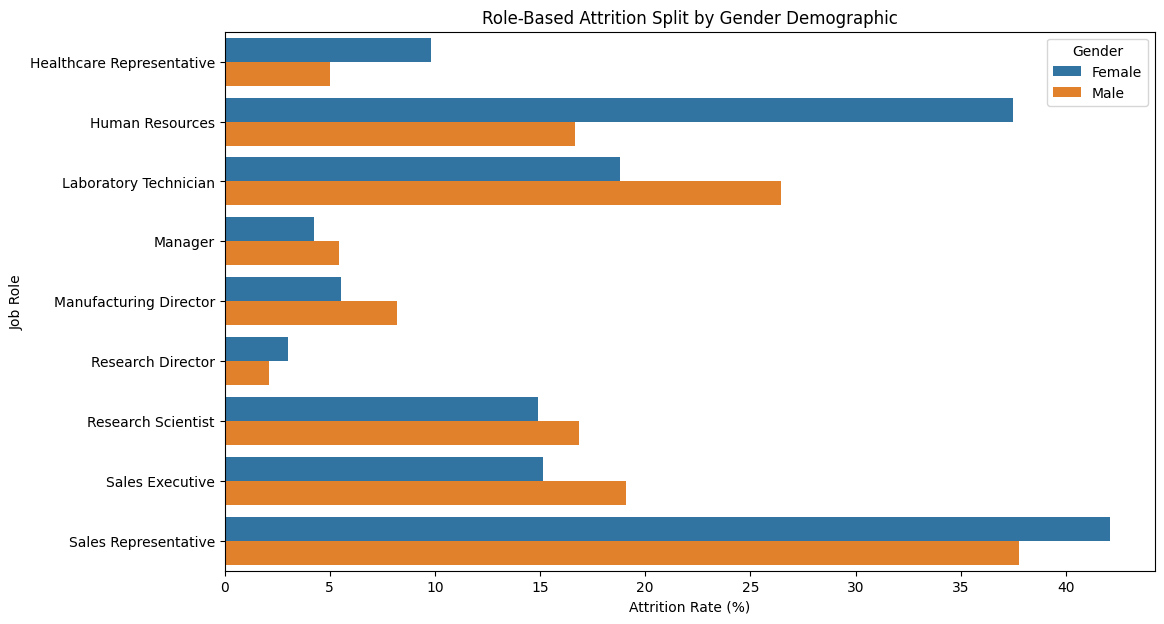

In [14]:
# Group by both role and gender to isolate demographic differences
demographic_rates = df.groupby(['JobRole', 'Gender'])['Attrition_Numberic'].mean().reset_index()
demographic_rates.columns = ['JobRole', 'Gender', 'Attrition_Rate']
demographic_rates['Attrition_Rate'] = demographic_rates['Attrition_Rate'] * 100

# Using the hue parameter to display gender side-by-side
plt.figure(figsize=(12, 7))
sns.barplot(x='Attrition_Rate', y='JobRole', hue='Gender', data=demographic_rates)

plt.title("Role-Based Attrition Split by Gender Demographic")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.show()

### 3.4.3 Key Findings & Interpretation

The gender-segmented distribution curves uncover the precise demographic vulnerabilities that overall role averages hide, pinpointing distinct imbalances within high-risk job tracks:

* **The Sales Representative Gender Disparity:** While Sales Representatives exhibit the highest turnover overall, **Male** employees in this role face a disproportionately severe attrition risk, climbing close to **40%.** This indicates a stark variance in retention success between genders within the exact same department.
  
* **The Human Resources Divergence:** A highly pronounced inversion occurs within Human Resources, where **Female** turnover spikes dramatically above **25%,** significantly outstripping male attrition in the same role. This highlights a department-specific demographic vulnerability that demands targeted investigation.

* **Balanced High-Risk Zones:** In contrast to the variations above, roles like **Laboratory Technician** positions show relatively parallel attrition curves, hovering closely between **20% and 25%** for both male and female groups. This implies that the underlying drivers in these zones impact staff universally regardless of gender demographics.

### 3.4.4 Recommendations

* **Audit and Overhaul Sales Representative Culture & Workloads:** To tackle the near **40%** turnover peak among male Sales Representatives, conduct an internal audit focused on potential work-life balance imbalances or misaligned commission incentives. Structure mentorship programs or target peer support networks to address early career frustration points unique to this segment.
  
* **Review Equality and Support Pathways in Human Resources:** Address the steep **>25%** female attrition rate in HR by creating clear organizational pathways for advancement and burnout relief. Investigate department-specific pressures, ensure workload distributions are equitable, and introduce flexible work structures to insulate this critical administrative group.

  
* Standardize Operational Support for Laboratory Technicians: Because attrition sits at a universally high **20%–25%** across all genders for Lab Technicians, interventions must be broad and structural. Focus on general workplace improvements, such as hazard-reduction protocols, optimized shift planning, and updated laboratory equipment, to uplift retention metrics across the board.

### 3.4.5 Theoretical Lens: Social Role Theory

To explain why demographic segments experience divergent attrition peaks within identical functional roles, we look at the data through the framework of **Social Role Theory.** This model examines how institutionalized behavioral expectations and workplace environments interact with gender norms:

* **Role-Congruity Strain (Sales Disparity):** High-pressure sales roles often demand an aggressively competitive environment. The stark **40%** peak in male turnover suggests a heightened susceptibility to burnout when these competitive subcultures are poorly managed or lack structural support systems, turning a stereotypically aligned environment into a high-attrition trap.
  
* **Workplace Isolation & Emotional Labor (HR Divergence):** HR positions demand immense emotional labor, which often disproportionately burdens female employees due to historical societal expectations surrounding conflict resolution. When organizational support structures collapse, female HR professionals face elevated stress, resulting in the **25%** turnover spike as they seek out less draining professional landscapes.

  
* **Structural Neutrality (Laboratory Technicians):** In technical, highly structured laboratory environments, operational stress stems almost entirely from lab workflows, equipment quality, and rigid shifts rather than gendered social dynamics. The parallel **20%–25%** curve proves that systemic mechanical stressors bypass demographic differences entirely.

  
**Theoretical Attribution:** The data shows that turnover imbalances are heavily driven by **demographic-role friction** and universal workplace stressors rather than individual lack of talent. When social expectations amplify role stress, demographic pockets fracture; when operational stress dominates, the entire workforce is impacted uniformly.

### 3.4.6 Conclusion on Hypothesis 4 (H₁)

The distribution data strongly validates our **Alternative Hypothesis (H₁)**. Rather than being a uniform risk across demographics, role-driven attrition is concentrated heavily within specific gender pockets depending on the occupational department, indicating that certain role profiles create localized vulnerability segments requiring distinct, customized corporate oversight.

## 3.5 Work-Life Balance and Commute Distance Breakdown

Not every employee shares the same daily commute length or personal responsibilities outside of office hours. This section analyzes how physical distance from home interacts with subjective work-life balance scores to drive voluntary attrition, and examines if these geographic and structural pressures manifest differently across specific corporate departments.

* **Null Hypothesis (H₀) :** Attrition rates are uniform across all commute distances and work-life balance tiers, and an employee's department has no bearing on voluntary turnover patterns within those factors.
  
* **Alternative Hypothesis (H₁):** Employees facing longer commutes who report lower work-life balance scores suffer from disproportionately high attrition rates, with certain organizational departments showing increased vulnerability to these combined pressures.
  
**Translation:** We are trying to find out if a long drive to work plus low work-life balance makes people quit, and see if this problem is worse in certain departments.

### 3.5.1 Variable Mapping & Data Approach

To analyze how environmental travel strains interact with subjective work-life balance domains, we map our psychological variables to the following dataset fields:

*   **Independent Variables (Predictors):**

    •   DistanceFromHome (Continuous Numeric Value) — representing the physical geographic boundary strain.

    •   WorkLifeBalance (Discrete Ordinal Survey Tiers: 1 to 4) — representing the employee's perceived quality-of-life boundaries.

    •   Department (Categorical) — representing the unique localized operational subculture (Sales, R&D, HR).
        
*   **Dependent Variable (Outcome):** Attrition (Categorical: Yes / No) — representing the resulting behavioral action.

**Analytical Plan:** We will construct a multi-dimensional visualization to evaluate the average commute distances across individual work-life balance rating levels. By applying a departmental filter layer, we can check if combined geographic and balance friction triggers localized turnover peaks.

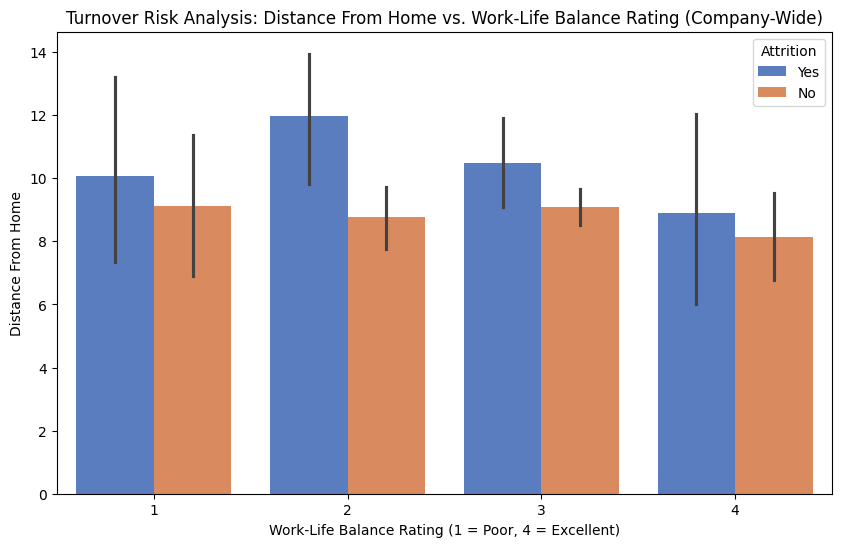

In [15]:
# Set up the visualization canvas
plt.figure(figsize=(10, 6))

# Comparing commute distance across work-life balance tiers
sns.barplot(x='WorkLifeBalance',y='DistanceFromHome',hue='Attrition',data=df,palette='muted')

# Customizing titles and labels for clarity
plt.title("Turnover Risk Analysis: Distance From Home vs. Work-Life Balance Rating (Company-Wide)")
plt.xlabel("Work-Life Balance Rating (1 = Poor, 4 = Excellent)")
plt.ylabel("Distance From Home")
plt.show()

The chart demonstrates a distinct relationship between commuting proximity, quality-of-life ratings, and employee retention. Across almost all work-life balance tiers, employees who leave the company (represented by the blue bars) exhibit a higher average distance from home compared to those who stay (represented by the orange bars), with the most pronounced distance gap occurring among employees who rate their balance at the lowest tier **(1)**. 

This initial finding indicates that the combination of poor work-life balance and long commutes correlates with higher overall turnover. However, looking at broad company-wide averages can mask how these dual pressures change based on specific workplace environments. To pinpoint whether this commuting strain affects all business segments equally or targets specific operational fields, we need to analyze these variables across individual departments using a segmented side-by-side breakdown.

### 3.5.2 Commute & Balance Friction by Department Breakdown

To pinpoint whether travel strain affects all business segments equally or targets specific operational fields, we break down our variables across individual departments using a segmented side-by-side breakdown.

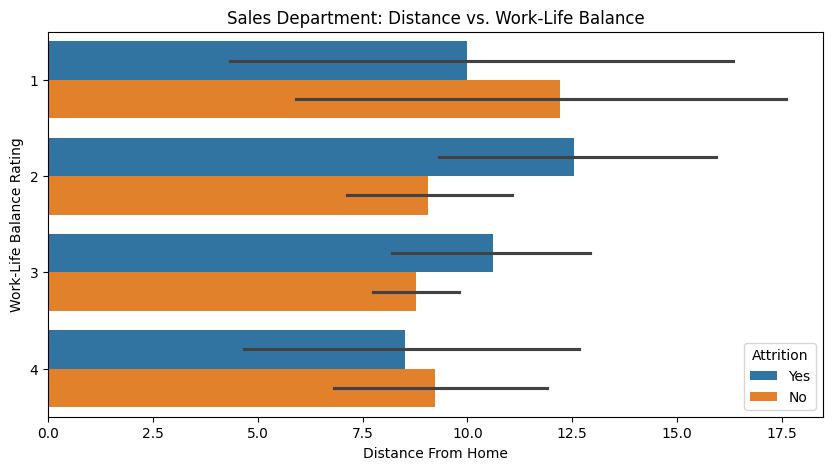

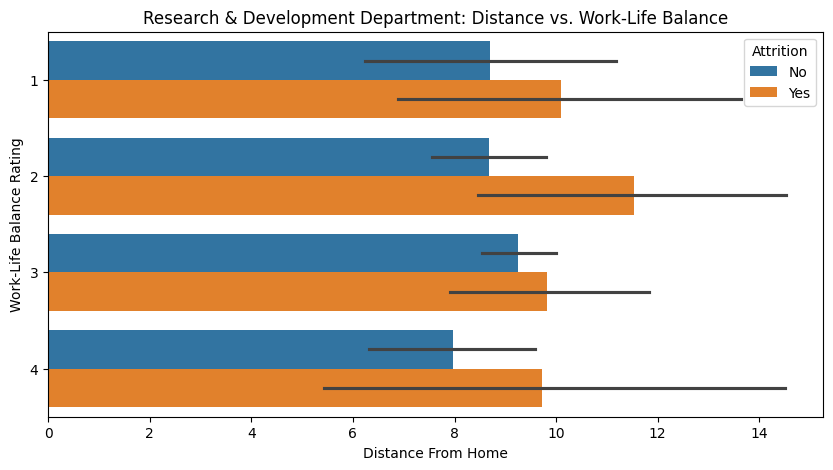

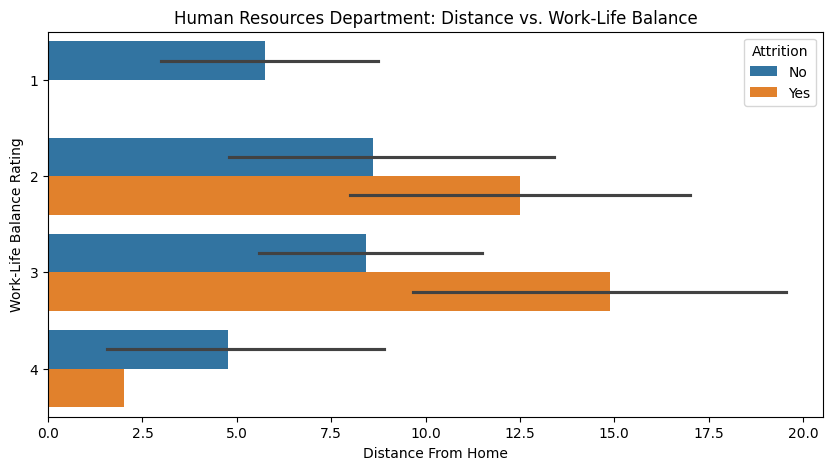

In [16]:
# Department wise breakdown

# Get the unique departments to loop through them
departments = df['Department'].unique()

# Create a separate bar chart for each department 
for dept in departments:
    # Filter a subset of the data for specific department
    dept_data = df[df['Department'] == dept]
    
    # Set the width & height of the figure
    plt.figure(figsize=(10, 5))
    
    # Horizontal bar chart with a hue filter 
    sns.barplot(x='DistanceFromHome',y='WorkLifeBalance',hue='Attrition',data=dept_data,orient='h')
    
    # Add labels and title
    plt.title(f"{dept} Department: Distance vs. Work-Life Balance")
    plt.xlabel("Distance From Home")
    plt.ylabel("Work-Life Balance Rating")
    
    # Display the chart
    plt.show()

### 3.5.3 Key Findings & Interpretation

The department-segmented bar distributions uncover localized geographic and balance-related vulnerabilities that company-wide averages obscure, exposing unique behavioral patterns across different units:

* **The Sales Department Commute Vulnerability:** Within the Sales Department, employees who leave the company consistently display a higher average distance from home across almost all work-life balance tiers. This gap is most severely pronounced at Rating **1** and Rating **2**, indicating that sales staff are particularly sensitive to geographic displacement when combined with lower quality-of-life markings.
  
* **The Research & Development Neutral Matrix:** In contrast, the Research & Development Department displays remarkably stable, parallel average distances between the retained and departed groups across tiers **2, 3, and 4.** At tier **2**, the leaving group actually registers a slightly lower average distance, showing that commute length behaves as a less dominant catalyst for attrition within technical environments.

* **The Human Resources Volatility & Data Skew:** The Human Resources Department displays extreme visual variance, particularly at **Rating 1** where the "No" attrition bar is completely isolated and at **Rating 3** where the "Yes" attrition bar spikes radically. This erratic distribution is heavily reflective of a small overall headcount baseline within the department, highlighting that single departures can heavily alter statistical averages.

### 3.5.4 Recommendations

* **Implement Geographic Boundaries and Travel Subsidies for Sales Roles:** Because Sales employees leaving the firm show a clear commute vulnerability at **Ratings 1 and 2,** regional territory planning must minimize travel stress. Offer strategic options such as regional client reassignments, commuter rideshare stipends, or dedicated high-speed transit subsidies to reduce geographic strain on high-risk staff.
  
* **De-prioritize Commute Triggers in Technical R&D Retention Strategies:** Since R&D attrition remains highly stable and independent of distance across tiers **2, 3, and 4,** standard commute-reduction plans will yield diminishing returns here. Instead, focus R&D retention efforts on technical resources, project tools, internal development opportunities, and career growth pathways.

  
* **Establish Long-Term HR Aggregation Buffers to Counter Data Volatility:** The extreme visual variance and erratic spikes in Human Resources **(Rating 1 and 3)** point to low sample sizes. To prevent single administrative departures from skewing organizational policies, aggregate HR demographic records across multiple fiscal years before implementing localized work-life balance initiatives.

### 3.5.5 Theoretical Lens: Border Theory

To explain why the intersection of commute length and work-life balance ratings varies widely across different corporate segments, we examine the trends through **Border Theory.** This framework models how individuals navigate the daily borders between the domains of "work" and "home":

* **Border Permeability & Exhaustion (Sales Vulnerability):** Sales professionals operate in an outward-facing domain with highly elastic boundaries (e.g., variable client visits and erratic quotas). When long physical commute distances are paired with low work-life integration **(Ratings 1 & 2)**, the border between work and home collapses entirely, leading to extreme role conflict and localized attrition.
  
* **High Domain Segmentation (R&D Stability):** R&D engineering and research roles are naturally highly segmented, often tied to dedicated laboratory facilities or predictable sprint cycles. Because their day-to-day work domain features rigid borders, employees maintain stable expectations; as a result, physical distance variation across tiers **2, 3, and 4** plays a negligible role in driving turnover.

  
* **Border Instability due to Sample Limitations (HR Anomalies):** The sudden spikes in HR highlight an analytical constraint where individual border friction cannot be generalized. Small operational teams experience severe structural instability whenever a single boundary relationship breaks down, causing massive statistical shifts rather than indicating a systemic workforce pattern.
Theoretical Attribution: The data shows that geographic distance is not an absolute turnover trigger. It becomes destructive only when an employee's professional domain features highly permeable or poorly bounded structures (like Sales), whereas highly segmented domains (like R&D) are naturally insulated from commute-driven friction.

### 3.5.6 Conclusion on Hypothesis 5 (H₁)

The segmented data partially validates our **Alternative Hypothesis (H₁).** Rather than showing a uniform company-wide trend, the interaction between long travel distances and poor work-life balance acts as an active turnover driver primarily within the **Sales Department**, while proving less critical or statistically volatile in technical and smaller administrative environments.

# 4. Strategic Workforce Insights & Action Plan


## 4.1 Integrated Attrition Risk Matrix

By bringing together the insights from our five hypotheses, we can see that employees do not leave for just one reason. Instead, turnover happens when work stress, financial motivation, and relationship issues pile up.
We can sort our findings into three clear priority levels based on how severely they impact employee psychology and behavior:

* **Tier 1: Immediate Behavioral Flight Risks (Critical Priority):**
  
	• Male Sales Representatives: This group has the highest turnover rate in the company, climbing close to **40%**. The data shows they are highly sensitive to long commutes, which ruin their daily work-life balance .

	• Employees with Zero Stock Options (Level 0): This group has a massive **24%** turnover rate. Because they have no long-term financial stake or ownership in the company, they have very little psychological commitment to stay.

	• The Overtime Burnout Trigger: Working extra hours pushes Sales turnover past **32%** and triples the turnover rate for Research & Development (R&D) staff from **10% to ~26**.

* **Tier 2: Relationship & Career Milestone Vulnerabilities (Medium Priority):**

	• The 0–12 Month "Manager-Transition" Window: Turnover peaks sharply in the very first year **(Year 0)**. This points to a breakdown during the early stage where a manager and a new employee are still trying to adapt to each other's styles.

	• Female Human Resources (HR) Professionals: This group shows a distinct spike in turnover, climbing past **25%**. This suggests unique departmental or cultural pressures affecting female staff in HR roles.

	• The Year 2 Career Exit Gate: Employees who do not feel valued or supported by their manager tend to hit a breaking point around **Year 2** and choose to leave the company entirely.

* **Tier 3: Stable Roles or Small-Sample Fluctuations (Monitored Priority):**

	• Laboratory Technicians: Attrition sits at a steady **20%–25%** across all genders. This tells us that turnover here is caused by the physical nature of laboratory work shifts rather than gender dynamics.

	• R&D Commutes: R&D employees do not care about commute distance.Their motivation is tied strictly to their technical projects, making physical location a non-issue.

	• HR Data Skews: The wild spikes in HR numbers at ratings 1 and 3 are simply due to a very small headcount. Losing just one or two people completely shifts the percentages, so we shouldn't mistake this for a massive cultural crisis.

## 4.2 High-Risk Employee Profile (The Psychological Persona)

By looking at the behavioral patterns in our data, we can create a composite profile of the employee who is most likely to experience severe burnout and resign:

**[High Risk-Retention Profile]**

**Role:** Sales Representative (Male Profile)

**Compensation:** No Stock Options (Level 0 Equity)

**Workload:** High Overtime (Chronic Stress / Sprint Cycles)

**Geography:** Commute Distance Over 15 units (High Work-Family Conflict)

**Tenure:** Working with a New Manager for Less Than 1 Year

If an employee matches three or more of these boxes, they are facing a high psychological strain and are at immediate risk of leaving the firm.

## 4.3 Multi-Phased Strategic Roadmap

To solve these issues, the company needs a step-by-step plan that addresses immediate stress first, followed by structural changes to compensation and leadership habits:

* **Phase 1: Quick-Fix Stress Relief (Months 0–3):**

	• Cap Overtime Hours: Set strict weekly limits on extra hours to prevent R&D and tech workers from hitting the 26% burnout threshold.

	• New Manager Check-ins: Create a mandatory 90-day transition program whenever an employee gets a new supervisor. Formal check-ins at days 30, 60, and 90 will catch early personality clashes before they lead to a resignation.

* **Phase 2: Adjusting Rewards and Work Boundaries (Months 3–12):**

	• Give Everyone a Stake: Eliminate Level 0 equity. Transitioning entry-level employees into a basic stock program within their first year gives them a strong psychological sense of ownership.

	• Fix Sales Commutes: Adjust sales territories so employees don't have to drive long distances while dealing with high-stress targets.

	• Mid-Point Career Reviews: Have growth-focused career conversations with employees around their 18th month to intercept the Year 2 turnover wave.

* **Phase 3: Long-Term Relationship Building (Months 12+):**

	• Reward Supportive Managers: Tie a portion of a manager's performance bonus directly to how well they retain their team members, encouraging healthier leadership habits.

	• Better HR Data Tracking: Wait and combine several years of HR data before changing policies, ensuring decisions aren't being skewed by a few isolated departures.

# 5. Conclusion

This project demonstrates how data analysis allows us to look past simple company averages and pinpoint the exact moments, departments, and roles where employees are struggling.
The data delivers a clear psychological conclusion: employees are highly motivated to stay when they feel a sense of ownership through long-term financial rewards (Level 1 & 2 Equity) and when they have stable, high-trust relationships with their supervisors (Year 4+ stability). On the other hand, turnover skyrockets when systemic stressors are ignored—such as chronic overtime crushing R&D teams, long commutes overlapping with high sales pressure, or a total lack of communication during a new hire's first year.
By shifting from a reactive approach to a proactive retention strategy based on these psychological insights, leadership can create a healthier corporate culture. This data-driven approach will not only save the company massive turnover costs but will also significantly protect employee well-being, morale, and long-term organizational health.